In [3]:
import tensorflow as tf
from keras.datasets import fashion_mnist
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import EarlyStopping
from keras.applications.vgg16 import VGG16, preprocess_input
from keras.optimizers import RMSprop
import matplotlib.pyplot as plt

# Частина 1

In [4]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.16,
    random_state=42,
    stratify=y_train
)

x_train = x_train.reshape((50400, 28, 28, 1))
x_test = x_test.reshape((10000, 28, 28, 1))
x_val = x_val.reshape((9600, 28, 28, 1))


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [23]:
model = Sequential()
model.add(Conv2D(16, (3, 3), activation="relu", padding="same", input_shape=(28, 28, 1)))
model.add(Conv2D(32, (3, 3), activation="relu", padding="same"))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(64, (3, 3), activation="relu", padding="same"))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(128, (3, 3), activation="relu", padding="same"))
model.add(MaxPooling2D((2, 2)))

model.add(Flatten())
model.add(Dropout(0.5))

model.add(Dense(256, activation="relu"))
model.add(Dense(10, activation="softmax"))

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

In [24]:
train_datagen = ImageDataGenerator(
    # rotation_range=15,
    # width_shift_range=0.1,
    # height_shift_range=0.1,
    # shear_range=5,
    # zoom_range=0.1,
    # horizontal_flip=True,
    # fill_mode="nearest"
    )

val_datagen = ImageDataGenerator()
test_datagen = ImageDataGenerator()

train_generator = train_datagen.flow(
    x_train,
    y_train,
    batch_size=64,
    shuffle=True
)

val_generator = val_datagen.flow(
    x_val,
    y_val,
    batch_size=64,
    shuffle=False
)

test_generator = test_datagen.flow(
    x_test,
    y_test,
    batch_size=64,
    shuffle=False
)

In [25]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_generator,
    epochs=15,
    validation_data=val_generator,
    callbacks=[early_stopping]
    )


Epoch 1/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 182s 229ms/step - accuracy: 0.7985 - loss: 0.5516 - val_accuracy: 0.8768 - val_loss: 0.3412
Epoch 2/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 198s 252ms/step - accuracy: 0.8769 - loss: 0.3356 - val_accuracy: 0.9028 - val_loss: 0.2679
Epoch 3/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 227s 289ms/step - accuracy: 0.8968 - loss: 0.2800 - val_accuracy: 0.9098 - val_loss: 0.2389
Epoch 4/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 221s 281ms/step - accuracy: 0.9073 - loss: 0.2497 - val_accuracy: 0.9190 - val_loss: 0.2178
Epoch 5/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 196s 248ms/step - accuracy: 0.9180 - loss: 0.2263 - val_accuracy: 0.9239 - val_loss: 0.2046
Epoch 6/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 217s 276ms/step - accuracy: 0.9213 - loss: 0.2092 - val_accuracy: 0.9287 - val_loss: 0.1880
Epoch 7/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 205s 260ms/step - accuracy: 0.9260 - loss: 0.1944 - val_accuracy: 0.9310 - val_loss: 0.1896
Epoch 8/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 174s 221ms/step - accuracy: 0.9312 -

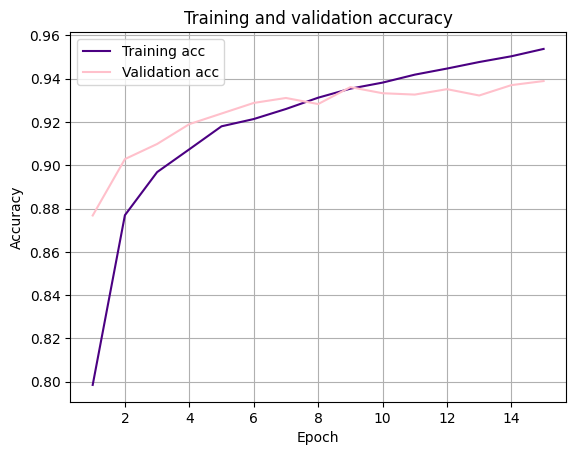

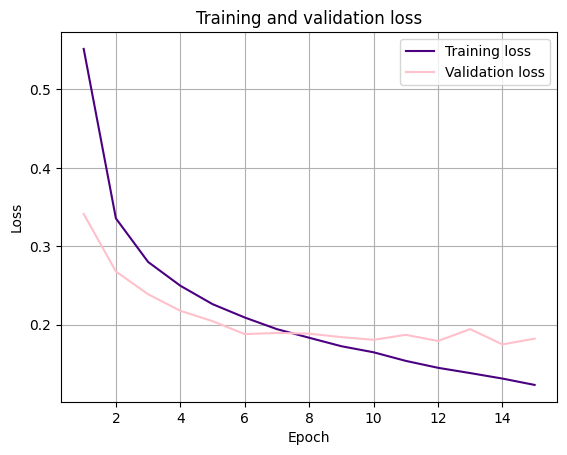

In [26]:
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]

loss = history.history["loss"]
val_loss = history.history["val_loss"]

epochs = range(1, len(acc) + 1)

plt.plot(epochs, acc, label="Training acc", color = "indigo")
plt.plot(epochs, val_acc, label="Validation acc", color = "pink")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and validation accuracy")
plt.grid(True)
plt.legend()

plt.figure()

plt.plot(epochs, loss, label="Training loss", color = "indigo")
plt.plot(epochs, val_loss, label="Validation loss", color = "pink")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and validation loss")
plt.grid(True)
plt.legend()
plt.show()


In [28]:
test_loss, test_acc = model.evaluate(test_generator)
print("test acc:", test_acc)

157/157 ━━━━━━━━━━━━━━━━━━━━ 11s 69ms/step - accuracy: 0.9254 - loss: 0.2024
test acc: 0.9254000186920166


## Висновки:
Найвища точність на тренувальній і валідаційній вибірці становила 0.9537 і 0.9389 відповідно, а на тесті точність має значення 0.9254. Було проведено декілька експеремнтів із архітектурою та аугментацією. Розширення даних тільки погрішило початкову точність 0.9309 на валідації, і зміна кількості нейронів Dense-шару з 512 до 256, додавання початкових 16 карт ознак, впровадження дропауту також не покращило результати. Тож, було прийнято рішення прибрати аугментацію і залишити змінену архітектуру мережі. Від цього остаточна точність досягла свого максимуму у цьому експеремнті. Порівняно із згортковою мережою, реалізованою у попередньому завданні, відчутних змін точності не прослідковується і в обох випадках максимальне значення було приблизно 0.94 на валідаційній вибірці. На тесті значення точності трохи зменшувалось, але залишалось у діапазоні між 0.90 і 0.93.

# Частина 2

## Виділення ознак

In [5]:
def prepare_vgg(x, y):
    x = tf.image.resize(x, (32, 32))
    x = tf.image.grayscale_to_rgb(x)
    x = preprocess_input(x * 255.0)
    return x, y

train_vgg = tf.data.Dataset.from_tensor_slices(
    (x_train, y_train)
).shuffle(5000).map(prepare_vgg).batch(64)

val_vgg = tf.data.Dataset.from_tensor_slices(
    (x_val, y_val)
).map(prepare_vgg).batch(64)

test_vgg = (
    tf.data.Dataset.from_tensor_slices((x_test, y_test))
    .map(prepare_vgg)
    .batch(64)
)

train_vgg = train_vgg.prefetch(tf.data.AUTOTUNE)
val_vgg = val_vgg.prefetch(tf.data.AUTOTUNE)

conv_base = VGG16(weights="imagenet", include_top=False, input_shape=(32, 32, 3))
conv_base.trainable = False

model_2 = Sequential()
model_2.add(conv_base),
model_2.add(Flatten()),
model_2.add(Dense(256, activation="relu")),
model_2.add(Dense(10, activation="softmax"))

model_2.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=RMSprop(learning_rate=1e-5),
    metrics=["accuracy"]
)

conv_base.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 8, 8, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 4, 4, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 2, 2, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 1, 1, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [6]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history_2 = model_2.fit(
    train_vgg,
    epochs=15,
    validation_data=val_vgg,
    callbacks = [early_stopping]
)

Epoch 1/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 19s 18ms/step - accuracy: 0.4300 - loss: 5.6177 - val_accuracy: 0.6020 - val_loss: 3.0069
Epoch 2/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.6546 - loss: 2.3551 - val_accuracy: 0.6828 - val_loss: 2.0238
Epoch 3/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.7094 - loss: 1.7621 - val_accuracy: 0.7195 - val_loss: 1.6595
Epoch 4/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.7374 - loss: 1.4922 - val_accuracy: 0.7393 - val_loss: 1.4635
Epoch 5/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.7548 - loss: 1.3252 - val_accuracy: 0.7542 - val_loss: 1.3326
Epoch 6/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.7688 - loss: 1.2065 - val_accuracy: 0.7621 - val_loss: 1.2406
Epoch 7/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.7776 - loss: 1.1142 - val_accuracy: 0.7711 - val_loss: 1.1689
Epoch 8/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.7857 - loss: 1.0408 - 

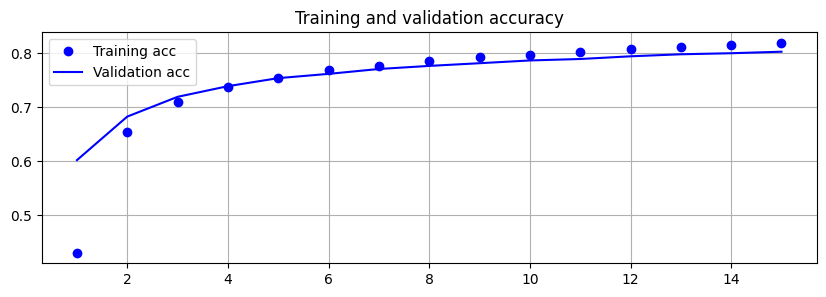

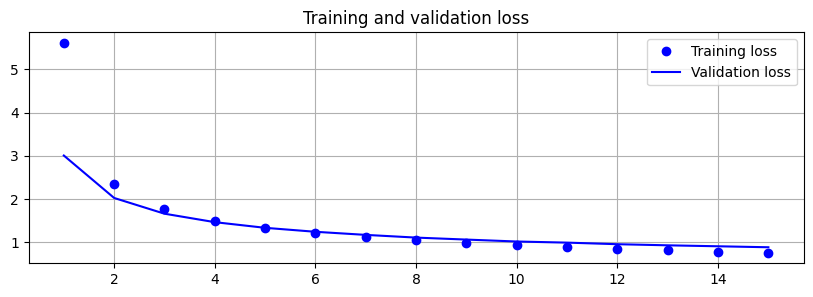

In [13]:
acc_2 = history_2.history["accuracy"]
val_acc_2 = history_2.history["val_accuracy"]

loss_2 = history_2.history["loss"]
val_loss_2 = history_2.history["val_loss"]

epochs_2 = range(1, len(acc_2) + 1)

plt.figure(figsize=(10, 3))
plt.grid(True)

plt.plot(epochs_2, acc_2, "bo", label="Training acc")
plt.plot(epochs_2, val_acc_2, "b", label="Validation acc")

plt.title("Training and validation accuracy")
plt.legend()

plt.figure(figsize=(10, 3))
plt.grid(True)

plt.plot(epochs_2, loss_2, "bo", label="Training loss")
plt.plot(epochs_2, val_loss_2, "b", label="Validation loss")
plt.title("Training and validation loss")

plt.legend()
plt.show()

## Донавчання

In [14]:
conv_base.trainable = True
set_trainable = False
for layer in conv_base.layers:
    if layer.name == "block5_conv1":
        set_trainable = True
    if set_trainable:
        layer.trainable = True
    else:
        layer.trainable = False


model_2.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=RMSprop(learning_rate=1e-5),
    metrics=["accuracy"]
)


In [16]:
# early_stopping = EarlyStopping(
#     monitor="val_loss",
#     patience=3,
#     restore_best_weights=True
# )

modified_history_2 = model_2.fit(
    train_vgg,
    epochs=15,
    validation_data=val_vgg,
    # callbacks = [early_stopping]
)

Epoch 1/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.9416 - loss: 0.1625 - val_accuracy: 0.8855 - val_loss: 0.3843
Epoch 2/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.9506 - loss: 0.1384 - val_accuracy: 0.8934 - val_loss: 0.3789
Epoch 3/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.9583 - loss: 0.1174 - val_accuracy: 0.8900 - val_loss: 0.3888
Epoch 4/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.9651 - loss: 0.1002 - val_accuracy: 0.8955 - val_loss: 0.3910
Epoch 5/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.9714 - loss: 0.0850 - val_accuracy: 0.8925 - val_loss: 0.3975
Epoch 6/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.9749 - loss: 0.0751 - val_accuracy: 0.8939 - val_loss: 0.4019
Epoch 7/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.9785 - loss: 0.0651 - val_accuracy: 0.8983 - val_loss: 0.4030
Epoch 8/15
788/788 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.9813 - loss: 0.0556 - 

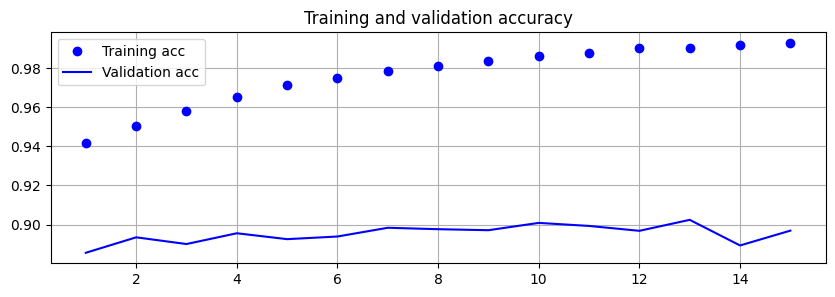

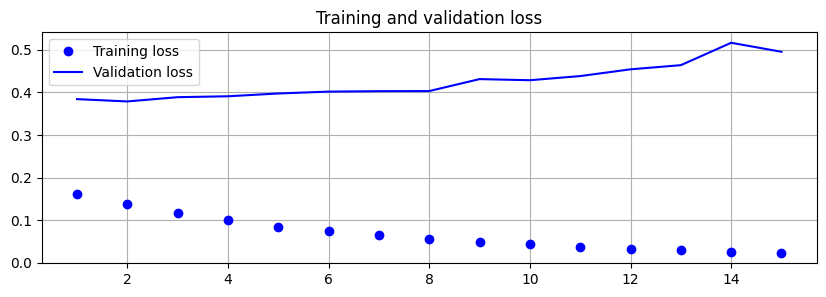

In [18]:
m_acc_2 = modified_history_2.history["accuracy"]
m_val_acc_2 = modified_history_2.history["val_accuracy"]

m_loss_2 = modified_history_2.history["loss"]
m_val_loss_2 = modified_history_2.history["val_loss"]

m_epochs_2 = range(1, len(m_acc_2) + 1)

plt.figure(figsize=(10, 3))
plt.grid(True)

plt.plot(m_epochs_2, m_acc_2, "bo", label="Training acc")
plt.plot(m_epochs_2, m_val_acc_2, "b", label="Validation acc")

plt.title("Training and validation accuracy")
plt.legend()

plt.figure(figsize=(10, 3))
plt.grid(True)

plt.plot(m_epochs_2, m_loss_2, "bo", label="Training loss")
plt.plot(m_epochs_2, m_val_loss_2, "b", label="Validation loss")
plt.title("Training and validation loss")

plt.legend()
plt.show()

In [19]:
test_loss, test_accuracy = model_2.evaluate(test_vgg)

print(f"Test accuracy: {test_accuracy:.4f}")

157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step - accuracy: 0.8937 - loss: 0.5507
Test accuracy: 0.8937


## Висновок:
Точність на тестовій вибірці становить 0.8937, що є значно нижчим показником ніж при звичайній згортковій мережі. Під час виділення ознак валідаційна точність не змогла перевищити 0.80, а донавчання мало свій максимум - 0.90. Тож, у цьому експеремнті, порівнюючи із попередніми завданнями, нові прийоми і вже навчена основа не допомогли вдосконалити модель